# Tugas Kelas — Ekstraksi Fitur Global dan Content-Based Image Retrieval (CBIR)
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339)
**Studi Kasus:** Pencarian Citra Tomat Berdasarkan Kemiripan Visual

Nama: Nadhif Rif'at Rasendriya

NIM: 235150201111074

Repository Github: [https://github.com/nadhif-royal/tomato-cbir-global-features](https://github.com/nadhif-royal/tomato-cbir-global-features)

---
### Alur sistem yang dibangun
```
citra → (1) persiapan → (2) segmentasi → (3) ekstraksi fitur global (warna + bentuk + tekstur)
      → (4) database fitur → (5) jarak & peringkat CBIR → (6) visualisasi → (7) analisis
      → (8) opsional: fitur lokal ORB
```
Materi **P17 (Ekstraksi Fitur Global & CBIR)** dan **P18 (Ekstraksi Fitur Lokal)**.


# Langkah 0 — Persiapan Lingkungan
## 0.1 Import pustaka dan pengaturan umum

In [1]:
import os, sys, glob, math, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import spearmanr, kendalltau
from skimage.feature import graycomatrix, graycoprops
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 9, "font.size": 9})
cv2.setRNGSeed(0)

IN_COLAB = "google.colab" in sys.modules
MAX_SIDE = 640
print("Colab:", IN_COLAB, "| OpenCV", cv2.__version__, "| NumPy", np.__version__)

Colab: True | OpenCV 5.0.0 | NumPy 2.1.3


**Penjelasan.** Pustaka yang dipakai: NumPy/Pandas (data & tabel fitur), OpenCV (segmentasi, kontur, ORB), scikit-image (GLCM), SciPy (morfologi & statistik peringkat) dan Matplotlib (visualisasi).
`cv2.setRNGSeed(0)` memastikan hasil segmentasi GrabCut sama setiap kali notebook dijalankan. Semua citra nanti diseragamkan ke sisi terpanjang 640 piksel agar fitur yang bergantung resolusi (misalnya kontras GLCM) dapat dibandingkan secara adil.

# Langkah 1 — Persiapan Citra
## 1.1 Mengunggah dan memuat 7 citra (5 database + 2 query)

In [2]:
DATA_DIR = "dataset"
EXTS = ("jpg", "jpeg", "png", "JPG", "JPEG", "PNG")

def find_images():
    db = sorted(sum([glob.glob(f"{DATA_DIR}/db_*.{e}") for e in EXTS], []))
    qr = sorted(sum([glob.glob(f"{DATA_DIR}/query_*.{e}") for e in EXTS], []))
    return db, qr

db_files, query_files = find_images()

if IN_COLAB and (len(db_files) != 5 or len(query_files) != 2):
    from google.colab import files
    os.makedirs(DATA_DIR, exist_ok=True)
    uploaded = files.upload()
    for name, content in uploaded.items():
        with open(os.path.join(DATA_DIR, name), "wb") as f:
            f.write(content)
    db_files, query_files = find_images()

assert len(db_files) == 5 and len(query_files) == 2, \
    f"Butuh 5 citra db_* dan 2 citra query_* di folder '{DATA_DIR}/' (ditemukan {len(db_files)} dan {len(query_files)})"

def load_image(path, max_side=MAX_SIDE):
    """Baca citra → RGB → ubah ukuran agar sisi terpanjang = max_side."""
    bgr = cv2.imread(path)
    h, w = bgr.shape[:2]; s = max_side / max(h, w)
    bgr = cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

names = [os.path.basename(p) for p in db_files + query_files]
images = {os.path.splitext(n)[0]: load_image(p) for n, p in zip(names, db_files + query_files)}
DB_KEYS = [os.path.splitext(os.path.basename(p))[0] for p in db_files]
Q_KEYS = [os.path.splitext(os.path.basename(p))[0] for p in query_files]

info = pd.DataFrame({"berkas": names,
                     "peran": ["database"]*5 + ["query"]*2,
                     "ukuran asli (px)": [f"{cv2.imread(p).shape[1]}x{cv2.imread(p).shape[0]}" for p in db_files + query_files],
                     "ukuran dipakai (px)": [f"{images[k].shape[1]}x{images[k].shape[0]}" for k in DB_KEYS + Q_KEYS]})
display(info)

Saving db_1_merah_bulat.jpg to db_1_merah_bulat.jpg
Saving db_2_hijau_mentah.jpg to db_2_hijau_mentah.jpg
Saving db_3_oranye_ceri.jpg to db_3_oranye_ceri.jpg
Saving db_4_merah_lonjong_plum.jpg to db_4_merah_lonjong_plum.jpg
Saving db_5_kuning_bergerombol.jpg to db_5_kuning_bergerombol.jpg
Saving query_1_merah_ceri.jpg to query_1_merah_ceri.jpg
Saving query_2_hijau_tangkai.jpg to query_2_hijau_tangkai.jpg


,berkas,peran,ukuran asli (px),ukuran dipakai (px)
0,db_1_merah_bulat.jpg,database,960x798,640x532
1,db_2_hijau_mentah.jpg,database,960x720,640x480
2,db_3_oranye_ceri.jpg,database,960x720,640x480
3,db_4_merah_lonjong_plum.jpg,database,960x640,640x427
4,db_5_kuning_bergerombol.jpg,database,960x640,640x427
5,query_1_merah_ceri.jpg,query,960x720,640x480
6,query_2_hijau_tangkai.jpg,query,950x983,619x640


## Sumber Gambar/Dataset Citra

1. **db_1_merah_bulat.jpg (Database 1)**

* Referensi: Softeis (2005) *Tomato je.jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Tomato_je.jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Tomato_je.jpg?width=800)


2. **db_2_hijau_mentah.jpg (Database 2)**

* Referensi: Cooper, C. (2016) *Green Tomato.jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Green_Tomato.jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Green_Tomato.jpg?width=800)


3. **db_3_oranye_ceri.jpg (Database 3)**

* Referensi: Rulkens, T. (2012) *Orange tomato (6951843461).jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Orange_tomato_(6951843461).jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Orange_tomato_(6951843461).jpg?width=800)


4. **db_4_merah_lonjong_plum.jpg (Database 4)**

* Referensi: Wikimedia Commons (2016) *Plum-tomato.jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Plum-tomato.jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Plum-tomato.jpg?width=800)


5. **db_5_kuning_bergerombol.jpg (Database 5)**

* Referensi: Lufa Farms (2012) *Lufa Farms Landmarks - Yellow Tomato.jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Lufa_Farms_Landmarks_-_Yellow_Tomato.jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Lufa_Farms_Landmarks_-_Yellow_Tomato.jpg?width=800)


6. **query_1_merah_ceri.jpg (Query 1)**

* Referensi: Rulkens, T. (2012) *Red tomato (6951842889).jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Red_tomato_(6951842889).jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Red_tomato_(6951842889).jpg?width=800)


7. **query_2_hijau_tangkai.jpg (Query 2)**

* Referensi: Toony (2006) *Unripe tomato on its stem.jpg*, Wikimedia Commons.
* Tautan: [https://commons.wikimedia.org/wiki/Special:FilePath/Unripe_tomato_on_its_stem.jpg?width=800](https://commons.wikimedia.org/wiki/Special:FilePath/Unripe_tomato_on_its_stem.jpg?width=800)

## 1.2 Menampilkan kelima citra database dan kedua citra query beserta nama berkasnya

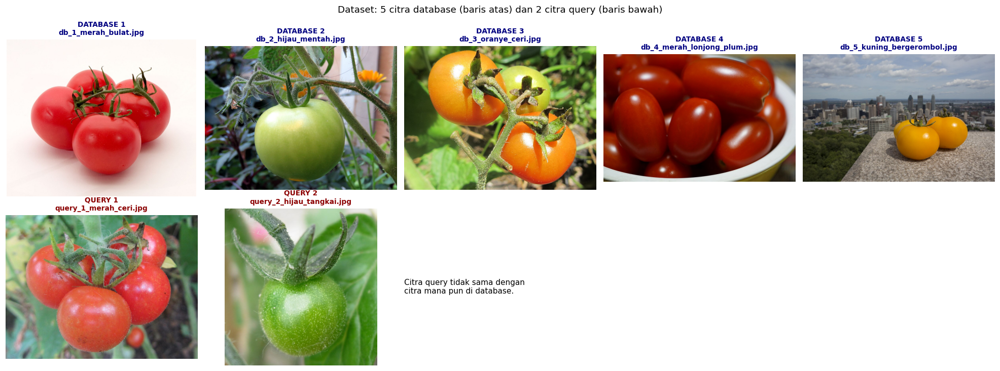

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6.6))
for ax in axes.ravel(): ax.axis("off")
for i, k in enumerate(DB_KEYS):
    axes[0, i].imshow(images[k]); axes[0, i].set_title(f"DATABASE {i+1}\n{k}.jpg", color="navy", fontweight="bold")
for i, k in enumerate(Q_KEYS):
    axes[1, i].imshow(images[k]); axes[1, i].set_title(f"QUERY {i+1}\n{k}.jpg", color="darkred", fontweight="bold")
axes[1, 2].text(0.0, 0.5, "Citra query tidak sama dengan\ncitra mana pun di database.", fontsize=10, va="center"); axes[1, 2].axis("off")
plt.suptitle("Dataset: 5 citra database (baris atas) dan 2 citra query (baris bawah)", fontsize=12, y=1.0)
plt.tight_layout(); plt.show()

**Penjelasan.** Dataset terdiri atas 5 citra database dan 2 citra query yang berbeda (query tidak ada di database). Variasi sengaja dipilih agar sistem CBIR diuji pada kondisi yang beragam:

| Berkas | Warna / kematangan | Bentuk | Latar belakang |
|---|---|---|---|
| db_1_merah_bulat | merah matang | bulat, bergerombol 4 buah | putih bersih |
| db_2_hijau_mentah | hijau muda (mentah) | bulat tunggal | kebun gelap |
| db_3_oranye_ceri | oranye (setengah matang) + 1 buah hijau | bulat, 3 buah | daun/tanah |
| db_4_merah_lonjong_plum | merah tua | lonjong (plum), banyak buah | mangkuk |
| db_5_kuning_bergerombol | kuning cerah | bulat, 2–3 buah | kota & langit |
| query_1_merah_ceri | merah matang | bulat, bergerombol | daun hijau |
| query_2_hijau_tangkai | hijau segar (mentah) | bulat tunggal | daun hijau kabur |

### Sumber citra
| Berkas | Halaman sumber (Wikimedia Commons) | Referensi |
|---|---|---|
| db_1_merah_bulat.jpg | File:Tomato je.jpg | Softeis (2005) _Tomato je.jpg_. Wikimedia Commons |
| db_2_hijau_mentah.jpg | File:Green Tomato.jpg | Cooper, C. / Prosthetic Head (2016) _Green Tomato.jpg_. Wikimedia Commons |
| db_3_oranye_ceri.jpg | File:Orange tomato (6951843461).jpg | Rulkens, T. (2012) _Orange tomato (6951843461).jpg_. Wikimedia Commons |
| db_4_merah_lonjong_plum.jpg | File:Plum-tomato.jpg | Wikimedia Commons (2016) _Plum-tomato.jpg_ |
| db_5_kuning_bergerombol.jpg | File:Lufa Farms Landmarks - Yellow Tomato.jpg | Lufa Farms (2012) _Lufa Farms Landmarks - Yellow Tomato.jpg_. Wikimedia Commons |
| query_1_merah_ceri.jpg | File:Red tomato (6951842889).jpg | Rulkens, T. (2012) _Red tomato (6951842889).jpg_. Wikimedia Commons |
| query_2_hijau_tangkai.jpg | File:Unripe tomato on its stem.jpg | Toony (2006) _Unripe tomato on its stem.jpg_. Wikimedia Commons |

Seluruh citra diunduh dari Wikimedia Commons dan diakses pada 15 Oktober 2026.

# Langkah 2 — Segmentasi Tomat
**Tujuan:** memisahkan objek tomat dari latar agar fitur dihitung **hanya pada objek**, bukan latar (syarat langkah 3).

Tantangan pada dataset ini: latar putih (db_1), tomat hijau di antara daun hijau (db_2, query_2), tomat dengan bunga oranye di latar (db_2), langit-kota (db_5), mangkuk (db_4), serta bayangan dan pantulan cahaya (_highlight_).
Satu ambang warna tetap tidak akan cocok untuk semuanya, sehingga digunakan pendekatan dua tahap.
## 2.1 Fungsi segmentasi: GrabCut + penyaringan warna dominan buah (HSV)

In [4]:
def dominant_hue(hsv, region):
    H, S, V = [hsv[..., i].astype(float) for i in range(3)]
    sel = region & (S > 70) & (V > 50)
    if sel.sum() < 50: sel = region
    hist = np.bincount(H[sel].astype(int), weights=(S * V)[sel], minlength=180)
    ext = np.concatenate([hist[-5:], hist, hist[:5]])
    sm = np.convolve(ext, np.ones(11) / 11, "same")[5:-5]
    return int(sm.argmax())

def hue_dist(H, h0):
    d = np.abs(H.astype(int) - h0); return np.minimum(d, 180 - d)

def segment_tomato(rgb, tol=30, s_min=50, v_min=40, keep_frac=0.12,
                   open_frac=0.035, close_frac=0.09, return_all=False):
    h, w = rgb.shape[:2]

    cv2.setRNGSeed(0)
    gc = np.zeros((h, w), np.uint8); bgd = np.zeros((1, 65)); fgd = np.zeros((1, 65))
    cv2.grabCut(rgb, gc, (int(.05*w), int(.05*h), int(.9*w), int(.9*h)), bgd, fgd, 6, cv2.GC_INIT_WITH_RECT)
    m0 = (gc == 1) | (gc == 3)

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    h0 = dominant_hue(hsv, m0)
    near = (hue_dist(hsv[..., 0], h0) <= tol) & m0 & (hsv[..., 1] >= 70) & (hsv[..., 2] >= v_min)
    s_med = np.median(hsv[..., 1][near]) if near.sum() > 50 else 100
    s_thr = max(s_min, 0.55 * s_med)
    keep = (hue_dist(hsv[..., 0], h0) <= tol) & (hsv[..., 1] >= s_thr) & (hsv[..., 2] >= v_min)
    mk = (m0 & keep).astype(np.uint8)

    kc = int(close_frac * max(h, w)) | 1
    enclosed = cv2.morphologyEx(mk, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kc, kc))) > 0
    mk = (mk.astype(bool) | (m0 & enclosed & (hsv[..., 2] >= 190))).astype(np.uint8)

    mk = cv2.morphologyEx(mk, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))) & m0.astype(np.uint8)
    mk = ndi.binary_fill_holes(mk).astype(np.uint8)

    k = int(open_frac * max(h, w)) | 1
    core = cv2.morphologyEx(mk, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    mk = (cv2.dilate(core, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))) & mk).astype(np.uint8)

    n, lab, st, _ = cv2.connectedComponentsWithStats(mk)
    if n > 1:
        big = st[1:, cv2.CC_STAT_AREA].max()
        mk = np.isin(lab, [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= keep_frac * big]).astype(np.uint8)
    mk = ndi.binary_fill_holes(mk).astype(np.uint8)
    mk = cv2.medianBlur(mk * 255, 5) // 255
    if return_all:
        return mk.astype(np.uint8), dict(grabcut=m0.astype(np.uint8), hue0=h0, s_thr=s_thr)
    return mk.astype(np.uint8)

print("Fungsi segment_tomato() siap dipakai.")

Fungsi segment_tomato() siap dipakai.


**Penjelasan.** Segmentasi dilakukan dalam tiga tahap:

1. **GrabCut (inisialisasi persegi)** menghasilkan kandidat objek tanpa perlu satu ambang warna yang sama untuk semua citra. Kelemahannya: kandidat sering ikut membawa bayangan, bunga, kota/langit, atau tepi mangkuk. `cv2.setRNGSeed(0)` dipakai agar hasilnya dapat diulang (reproducible).
2. **Penyaringan warna dominan.** Hue dominan buah dicari dari piksel jenuh di dalam kandidat (dengan **jarak hue melingkar**, karena merah berada di sekitar 0° dan 180° pada skala OpenCV). Piksel dipertahankan bila hue-nya dekat dengan hue dominan dan saturasinya cukup. Ambang saturasi dibuat **adaptif** (55% dari median saturasi buah) agar bayangan dan latar pucat terbuang. Pantulan cahaya (saturasi rendah, sangat terang) hanya diselamatkan bila **dikelilingi** oleh piksel buah (diuji dengan _closing_ berkernel besar), sehingga bayangan di luar kontur buah tidak ikut terambil.
3. **Operasi morfologi.** _Closing_ dan _fill holes_ menutup celah kecil. Lalu **_opening_ berkernel besar** (≈3,5% sisi terpanjang citra) membuang struktur yang tipis seperti tangkai, kelopak, dan daun **berdasarkan ukuran, bukan warna**, sehingga perlakuannya sama untuk tomat merah maupun hijau. Terakhir dibuang komponen kecil dan tepi dihaluskan dengan median blur.

Dengan cara ini tomat merah, oranye, kuning, maupun hijau dapat ditangani oleh prosedur yang sama; hanya hue dominan yang menyesuaikan diri secara otomatis.

## 2.2 Menerapkan segmentasi pada ketujuh citra: citra asli, mask, dan hasil segmentasi

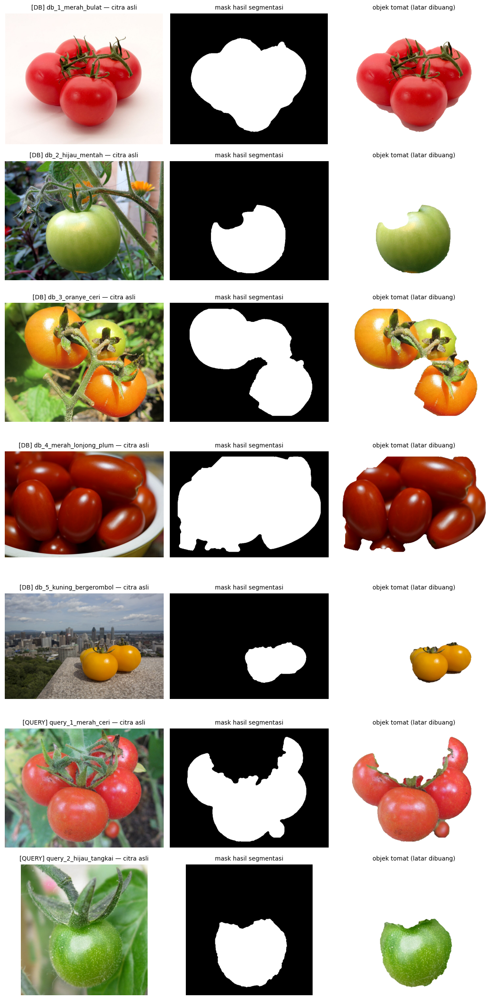

In [5]:
ALL_KEYS = DB_KEYS + Q_KEYS
masks, seg_info = {}, {}
for k in ALL_KEYS:
    masks[k], seg_info[k] = segment_tomato(images[k], return_all=True)

def object_only(rgb, mask, bg=255):
    out = rgb.copy(); out[mask == 0] = bg; return out

fig, axes = plt.subplots(len(ALL_KEYS), 3, figsize=(10.5, 3.0 * len(ALL_KEYS)))
for r, k in enumerate(ALL_KEYS):
    role = "DB" if k in DB_KEYS else "QUERY"
    axes[r, 0].imshow(images[k]); axes[r, 0].set_title(f"[{role}] {k} — citra asli")
    axes[r, 1].imshow(masks[k], cmap="gray"); axes[r, 1].set_title("mask hasil segmentasi")
    axes[r, 2].imshow(object_only(images[k], masks[k])); axes[r, 2].set_title("objek tomat (latar dibuang)")
    for c in range(3): axes[r, c].axis("off")
plt.tight_layout(); plt.show()

**Penjelasan.** Setiap baris menampilkan citra asli, mask biner (putih = objek tomat), dan hasil segmentasi di mana latar diganti putih. Hanya piksel pada mask inilah yang dipakai untuk ekstraksi fitur pada langkah 3.

## 2.3 Pemeriksaan kualitas segmentasi
### a) Perbandingan GrabCut saja vs metode akhir, dan statistik mask

,hue dominan (0–179),ambang S adaptif,luas GrabCut (%),luas mask akhir (%),piksel dibuang filter warna (%),jumlah komponen,menyentuh tepi citra
citra,,,,,,,
db_1_merah_bulat,2,102.8,40.8,34.7,15.0,1,False
db_2_hijau_mentah,37,88.0,23.2,19.0,18.1,1,False
db_3_oranye_ceri,15,118.8,37.7,38.9,0.7,1,False
db_4_merah_lonjong_plum,5,139.2,69.0,66.2,4.1,1,False
db_5_kuning_bergerombol,18,139.7,32.8,10.3,68.7,1,False
query_1_merah_ceri,3,95.2,40.3,36.2,10.3,1,False
query_2_hijau_tangkai,43,99.0,24.1,22.8,5.5,1,False


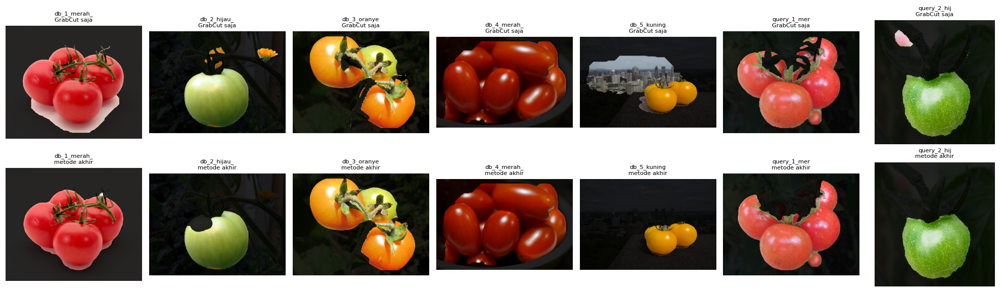

In [6]:
rows = []
for k in ALL_KEYS:
    mk = masks[k]; gc = seg_info[k]["grabcut"]
    n_cc = cv2.connectedComponents(mk)[0] - 1
    touches = (mk[0].any() or mk[-1].any() or mk[:, 0].any() or mk[:, -1].any())
    rows.append({"citra": k, "hue dominan (0–179)": seg_info[k]["hue0"], "ambang S adaptif": round(seg_info[k]["s_thr"], 1),
                 "luas GrabCut (%)": round(100 * gc.mean(), 1), "luas mask akhir (%)": round(100 * mk.mean(), 1),
                 "piksel dibuang filter warna (%)": round(100 * (gc.sum() - (gc & mk).sum()) / max(gc.sum(), 1), 1),
                 "jumlah komponen": n_cc, "menyentuh tepi citra": bool(touches)})
display(pd.DataFrame(rows).set_index("citra"))

fig, axes = plt.subplots(2, len(ALL_KEYS), figsize=(2.6 * len(ALL_KEYS), 5.3))
for c, k in enumerate(ALL_KEYS):
    for r, (m, ttl) in enumerate([(seg_info[k]["grabcut"], "GrabCut saja"), (masks[k], "metode akhir")]):
        ov = images[k].copy(); ov[m == 0] = (ov[m == 0] * 0.15).astype(np.uint8)
        axes[r, c].imshow(ov); axes[r, c].axis("off")
        axes[r, c].set_title(f"{k[:11]}\n{ttl}", fontsize=7.5)
plt.tight_layout(); plt.show()

### b) Validasi kuantitatif pada citra berlatar putih (db_1)
Tidak tersedia mask "kebenaran" (ground truth) untuk dataset ini. Sebagai pembanding sederhana, pada db_1 (latar putih bersih) dibuat mask acuan dengan **ambang Otsu pada kanal saturasi**, lalu dihitung _Intersection over Union_ (IoU) terhadap mask hasil metode.

In [7]:
k = "db_1_merah_bulat"
S_chan = cv2.cvtColor(images[k], cv2.COLOR_RGB2HSV)[..., 1]
_, ref = cv2.threshold(cv2.GaussianBlur(S_chan, (5, 5), 0), 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
ref = ndi.binary_fill_holes(cv2.morphologyEx(ref, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))).astype(np.uint8)
inter = (ref & masks[k]).sum(); union = (ref | masks[k]).sum()
print(f"IoU(mask metode, mask acuan Otsu-saturasi) pada {k}: {inter / union:.3f}")
print(f"Luas mask acuan: {100*ref.mean():.1f}% | luas mask metode: {100*masks[k].mean():.1f}%")

IoU(mask metode, mask acuan Otsu-saturasi) pada db_1_merah_bulat: 0.987
Luas mask acuan: 34.3% | luas mask metode: 34.7%


**Penjelasan.** Tabel menunjukkan seberapa besar filter warna "membersihkan" kandidat GrabCut. Pada db_5 (kota & langit), db_1 (bayangan) dan db_2/query_2 (bunga, daun) filter warna membuang area non-buah yang tidak dapat dibedakan GrabCut. Pada citra latar putih (db_1) metode akhir sangat dekat dengan mask acuan (IoU 0,987; luas mask 34,7% vs acuan 34,3%), artinya bayangan di bawah buah hampir seluruhnya terbuang.

**Keterbatasan yang diamati secara visual:** (i) tangkai panjang dan kelopak yang tipis dibuang berdasarkan ukuran (misalnya tangkai query_2), tetapi kelopak yang tebal atau menyatu dengan buah pada tomat bergerombol (db_3, query_1) masih sebagian ikut terambil, sehingga sisa tangkai/kelopak tidak sepenuhnya konsisten; (ii) pantulan cahaya yang berada tepat di tepi atas buah (db_2) membuat sebagian atas buah terpotong; (iii) pada db_4 tomat saling bertumpuk sehingga mask menyatu sebagai satu objek besar (bukan per-buah); (iv) pada query_1 terdapat takik kecil pada tepi buah di dekat tangkai. Keterbatasan ini dibahas lagi pada analisis (langkah 7).

# Langkah 3 — Ekstraksi Fitur Global (pada objek tomat saja)
Tiga kelompok fitur digunakan (lebih dari syarat minimal dua kelompok), sesuai materi P17:

| Kelompok | Fitur dalam vektor | Dimensi |
|---|---|---|
| **Warna** | mean R,G,B; std R,G,B; hue (representasi melingkar cos & sin); mean S; mean V | 10 |
| **Bentuk** | aspect ratio, circularity, solidity, extent | 4 |
| **Tekstur (GLCM)** | contrast, homogeneity, energy, correlation (rata-rata 4 sudut) | 4 |

Luas (area) dan keliling (perimeter) tetap dihitung dan ditampilkan pada tabel, tetapi **tidak dimasukkan ke vektor** karena bergantung pada jarak pemotretan/pemotongan citra, bukan pada sifat tomatnya (alasan lengkap di bawah).

## 3.1 Fitur warna (statistik warna + histogram hue)

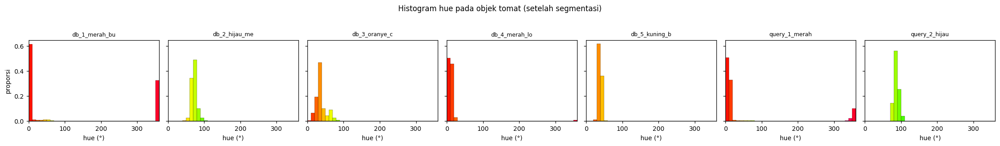

In [8]:
def color_features(rgb, mask):
    """Fitur warna dari piksel OBJEK saja (mask > 0)."""
    sel = mask > 0
    px = rgb[sel].astype(float) / 255.0
    mean, std = px.mean(0), px.std(0) # (materi P17: pendekatan statistik)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[sel].astype(float)
    ang = hsv[:, 0] * 2 * np.pi / 180.0
    wgt = (hsv[:, 1] / 255) * (hsv[:, 2] / 255) + 1e-6
    mean_angle = np.arctan2((wgt * np.sin(ang)).sum(), (wgt * np.cos(ang)).sum())
    return {"R_mean": mean[0], "G_mean": mean[1], "B_mean": mean[2],
            "R_std": std[0], "G_std": std[1], "B_std": std[2],
            "hue_cos": np.cos(mean_angle), "hue_sin": np.sin(mean_angle),
            "S_mean": hsv[:, 1].mean() / 255, "V_mean": hsv[:, 2].mean() / 255}, \
           float(np.degrees(mean_angle) % 360)

fig, axes = plt.subplots(1, len(ALL_KEYS), figsize=(2.9 * len(ALL_KEYS), 2.8), sharey=True)
for ax, k in zip(axes, ALL_KEYS):
    hsv = cv2.cvtColor(images[k], cv2.COLOR_RGB2HSV)[masks[k] > 0].astype(float)
    hist, edges = np.histogram(hsv[:, 0] * 2, bins=36, range=(0, 360), weights=(hsv[:, 1] * hsv[:, 2]) / 255**2)
    hist = hist / hist.sum()
    cols = [plt.cm.hsv(((edges[i] + edges[i+1]) / 2) / 360) for i in range(36)]
    ax.bar(edges[:-1], hist, width=10, align="edge", color=cols, edgecolor="k", linewidth=0.2)
    ax.set_title(k[:13], fontsize=8); ax.set_xlabel("hue (°)"); ax.set_xlim(0, 360)
axes[0].set_ylabel("proporsi")
plt.suptitle("Histogram hue pada objek tomat (setelah segmentasi)", y=1.04); plt.tight_layout(); plt.show()

**Penjelasan & alasan pemilihan fitur warna.** Perbedaan paling mencolok antar citra dataset adalah **warna/kematangan** (merah, oranye, kuning, hijau), sehingga warna dipilih sebagai kelompok utama.
- **Mean dan standar deviasi kanal RGB** adalah _statistical color features_ pada materi P17 (hitung manual mean, std, ...). Mean menyatakan warna dominan, std menyatakan keragaman warna (tomat hijau dengan bercak/pantulan memiliki std berbeda dari tomat merah rata).
- **Hue sebagai (cos, sin).** Hue adalah besaran melingkar: merah berada di sekitar 0° dan 360°. Jika hue dipakai langsung sebagai angka, merah muda (350°) dan merah (5°) tampak "berjauhan" padahal hampir sama. Dengan memetakan rata-rata sudut ke titik pada lingkaran (cos, sin) jarak antar warna menjadi benar.
- **Mean S dan V** menangkap kejenuhan dan kecerahan (tomat matang cenderung lebih jenuh dibanding yang mentah).
- **Histogram hue** dipakai di atas untuk membuktikan bahwa tiap kelas warna memiliki puncak yang berbeda; nilainya sudah terwakili oleh mean hue pada vektor fitur.
Semua nilai dihitung **hanya dari piksel pada mask** sehingga latar (langit, daun, mangkuk) tidak memengaruhi fitur.

## 3.2 Fitur bentuk

In [9]:
def shape_features(mask):
    """Fitur bentuk dari mask objek (seluruh komponen objek dianggap satu bentuk gabungan)."""
    m = (mask > 0).astype(np.uint8)
    sm = (cv2.GaussianBlur(m * 255, (0, 0), 2) > 127).astype(np.uint8)
    cnts, _ = cv2.findContours(sm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    A = sum(cv2.contourArea(c) for c in cnts); P = sum(cv2.arcLength(c, True) for c in cnts)
    pts = np.vstack(cnts)
    hull_A = cv2.contourArea(cv2.convexHull(pts))
    (_, _), (w, h), _ = cv2.minAreaRect(pts); L, W = max(w, h), max(min(w, h), 1e-6)
    x, y, bw, bh = cv2.boundingRect(pts)
    return {"area_ratio": A / m.size,                 # luas / luas citra  (informasi; tidak masuk vektor)
            "perimeter_px": P,                        # keliling (px)      (informasi; tidak masuk vektor)
            "aspect_ratio": L / W,                    # sisi panjang / sisi pendek rotated bounding box
            "circularity": 4 * math.pi * A / P**2,    # 4πA/P² — 1 untuk lingkaran sempurna (materi P17: roundness)
            "solidity": A / hull_A,                   # luas / luas convex hull — kecembungan
            "extent": A / (bw * bh)}                  # luas / luas bounding box

# Uji sanity
test_c = np.zeros((300, 300), np.uint8); cv2.circle(test_c, (150, 150), 100, 255, -1)
test_r = np.zeros((300, 300), np.uint8); cv2.rectangle(test_r, (50, 100), (250, 200), 255, -1)
print("Uji lingkaran         :", {k: round(v, 3) for k, v in shape_features(test_c).items() if k in ("aspect_ratio", "circularity", "solidity", "extent")})
print("Uji persegi panjang 2:1:", {k: round(v, 3) for k, v in shape_features(test_r).items() if k in ("aspect_ratio", "circularity", "solidity", "extent")})

Uji lingkaran         : {'aspect_ratio': 1.0, 'circularity': 0.902, 'solidity': 0.995, 'extent': 0.786}
Uji persegi panjang 2:1: {'aspect_ratio': 2.0, 'circularity': 0.709, 'solidity': 1.0, 'extent': 0.985}


**Penjelasan & alasan pemilihan fitur bentuk.** Bentuk membedakan tomat bulat dari tomat lonjong (plum, db_4) dan tomat tunggal dari yang bergerombol. Deskriptor mengikuti _Simple and Morphological Shape Descriptors_ pada materi P17:
- **Aspect ratio** (sisi panjang/sisi pendek _rotated bounding box_) – 1 untuk objek bulat, lebih besar untuk objek lonjong.
- **Circularity = 4πA/P²** (_roundness_) – bernilai 1 untuk lingkaran sempurna dan mengecil bila kontur tidak mulus atau objek bercabang.
- **Solidity = A/A_hull** – kecembungan; menurun bila ada cekungan/takik, misalnya gerombol buah dengan tangkai.
- **Extent = A/A_bbox** – seberapa penuh objek mengisi kotak pembatasnya.

Uji pada lingkaran dan persegi panjang 2:1 di atas memeriksa fungsi terhadap nilai teoretis: aspect ratio persegi panjang = 2,0 (teori 2), extent lingkaran = 0,786 (teori π/4 ≈ 0,785), circularity persegi panjang 0,709 (teori 4π·2/6² ≈ 0,698) dan circularity lingkaran 0,902 (teori 1; sedikit lebih kecil karena keliling pada piksel digital terukur lebih panjang daripada keliling ideal). Jadi nilai circularity absolut sedikit bias ke bawah, tetapi konsisten untuk semua citra sehingga tetap layak untuk perbandingan. Karena tepi digital kasar, keliling dihitung dari mask yang dihaluskan agar tidak membesar akibat "tangga" piksel.

**Mengapa area dan perimeter tidak masuk vektor?** Keduanya bergantung pada jarak pemotretan dan _cropping_ — tomat yang sama difoto dari dekat akan tampak "lebih besar". Rasio tak berdimensi (aspect ratio, circularity, solidity, extent) invarian terhadap skala sehingga lebih layak dibandingkan antar foto. Nilai `area_ratio` dan `perimeter_px` tetap ditampilkan di tabel sebagai informasi.

## 3.3 Fitur tekstur (GLCM pada objek saja)

In [10]:
GLCM_LEVELS = 32
GLCM_ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]

def texture_features(rgb, mask, levels=GLCM_LEVELS):
    """GLCM yang HANYA menghitung pasangan piksel di dalam objek: latar diberi level 0 lalu baris/kolom 0 dibuang."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    q = (gray.astype(float) / 256 * levels).astype(np.uint8) + 1
    q[mask == 0] = 0
    g = graycomatrix(q, [1], GLCM_ANGLES, levels=levels + 1, symmetric=True, normed=False)
    g = g[1:, 1:, :, :].astype(float)
    g = g / g.sum(axis=(0, 1), keepdims=True)
    return {p: float(graycoprops(g, p).mean()) for p in ["contrast", "homogeneity", "energy", "correlation"]}

img4 = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [0, 2, 2, 2], [2, 2, 3, 3]], np.uint8)
g_ref = graycomatrix(img4, [1], [0], levels=4, symmetric=False, normed=False)[:, :, 0, 0]
print("GLCM 0° citra 4×4 materi P17:\n", g_ref, "\n(cocok dengan matriks pada slide: [[2,2,1,0],[0,2,0,0],[0,0,3,1],[0,0,0,1]])")

GLCM 0° citra 4×4 materi P17:
 [[2 2 1 0]
 [0 2 0 0]
 [0 0 3 1]
 [0 0 0 1]] 
(cocok dengan matriks pada slide: [[2,2,1,0],[0,2,0,0],[0,0,3,1],[0,0,0,1]])


**Penjelasan & alasan pemilihan fitur tekstur.** Permukaan tomat berbeda tekstur: kulit halus-mengkilap (db_1, db_5) vs berbulu halus/bercak (query_1, query_2, db_3). Tekstur dihitung dengan **GLCM** (_Gray-Level Co-occurrence Matrix_, materi P17): matriks pasangan intensitas piksel bertetangga pada jarak d = 1 untuk sudut 0°, 45°, 90°, 135°, lalu fitur Haralick diambil dan **dirata-rata keempat sudut** agar tidak bergantung orientasi.
- **Contrast** — variasi intensitas lokal (tinggi bila permukaan "kasar"/ada pantulan tajam).
- **Homogeneity** — keseragaman (tinggi bila intensitas bertetangga mirip).
- **Energy** — keteraturan (tinggi bila pola berulang/seragam).
- **Correlation** — ketergantungan linear antar piksel bertetangga.

**Hal penting:** `skimage.graycomatrix` tidak mendukung mask. Agar latar tidak ikut dihitung, latar diberi level 0 dan baris/kolom 0 pada GLCM **dibuang** sebelum normalisasi, sehingga hanya pasangan piksel yang kedua-duanya berada di objek yang terhitung. Intensitas dikuantisasi menjadi 32 level (agar matriks tidak terlalu jarang) dan semua citra sudah diseragamkan ukurannya (langkah 1) supaya nilai kontras dapat dibandingkan.

## 3.4 Menggabungkan semua fitur dan menampilkan tabel numerik tiap citra

In [11]:
FEATURE_GROUPS = {
    "warna":   ["R_mean", "G_mean", "B_mean", "R_std", "G_std", "B_std", "hue_cos", "hue_sin", "S_mean", "V_mean"],
    "bentuk":  ["aspect_ratio", "circularity", "solidity", "extent"],
    "tekstur": ["contrast", "homogeneity", "energy", "correlation"],
}
FEATURE_ORDER = [f for g in FEATURE_GROUPS.values() for f in g]
print("Urutan fitur (", len(FEATURE_ORDER), "dimensi ):", FEATURE_ORDER)

def extract_features(rgb, mask):
    """Satu-satunya fungsi ekstraksi: dipakai IDENTIK untuk citra database dan query."""
    col, hue_deg = color_features(rgb, mask)
    shp = shape_features(mask)
    tex = texture_features(rgb, mask)
    allf = {**col, **shp, **tex}
    vec = np.array([allf[f] for f in FEATURE_ORDER], float)
    extra = {"hue_deg": hue_deg, "area_ratio": shp["area_ratio"], "perimeter_px": shp["perimeter_px"]}
    return vec, extra

feat, extra = {}, {}
for k in ALL_KEYS:
    feat[k], extra[k] = extract_features(images[k], masks[k])

F_all = pd.DataFrame(feat, index=FEATURE_ORDER).T
F_all.index.name = "citra"
display(Markdown("**Tabel A — Fitur warna** (nilai 0–1; hue dalam derajat hanya untuk informasi)"))
tA = F_all[FEATURE_GROUPS["warna"]].copy(); tA.insert(6, "hue (°)", [extra[k]["hue_deg"] for k in F_all.index])
display(tA.round(3))
display(Markdown("**Tabel B — Fitur bentuk** (kolom area & perimeter hanya informasi, tidak masuk vektor)"))
tB = F_all[FEATURE_GROUPS["bentuk"]].copy()
tB.insert(0, "area_ratio", [extra[k]["area_ratio"] for k in F_all.index]); tB.insert(1, "perimeter (px)", [extra[k]["perimeter_px"] for k in F_all.index])
display(tB.round(3))
display(Markdown("**Tabel C — Fitur tekstur GLCM** (rata-rata 4 sudut, d = 1, 32 level)"))
display(F_all[FEATURE_GROUPS["tekstur"]].round(4))

Urutan fitur ( 18 dimensi ): ['R_mean', 'G_mean', 'B_mean', 'R_std', 'G_std', 'B_std', 'hue_cos', 'hue_sin', 'S_mean', 'V_mean', 'aspect_ratio', 'circularity', 'solidity', 'extent', 'contrast', 'homogeneity', 'energy', 'correlation']


**Tabel A — Fitur warna** (nilai 0–1; hue dalam derajat hanya untuk informasi)

,R_mean,G_mean,B_mean,R_std,G_std,B_std,hue (°),hue_cos,hue_sin,S_mean,V_mean
citra,,,,,,,,,,,
db_1_merah_bulat,0.747,0.231,0.214,0.180,0.155,0.143,1.753,1.000,0.031,0.735,0.747
db_2_hijau_mentah,0.512,0.573,0.265,0.221,0.207,0.189,71.684,0.314,0.949,0.588,0.574
db_3_oranye_ceri,0.787,0.560,0.204,0.203,0.212,0.209,36.795,0.801,0.599,0.735,0.796
db_4_merah_lonjong_plum,0.497,0.118,0.048,0.154,0.141,0.137,9.266,0.987,0.161,0.928,0.497
db_5_kuning_bergerombol,0.719,0.466,0.035,0.190,0.137,0.091,37.820,0.790,0.613,0.934,0.719
query_1_merah_ceri,0.812,0.358,0.302,0.121,0.122,0.140,6.430,0.994,0.112,0.637,0.813
query_2_hijau_tangkai,0.478,0.649,0.250,0.142,0.132,0.212,85.660,0.076,0.997,0.657,0.649


**Tabel B — Fitur bentuk** (kolom area & perimeter hanya informasi, tidak masuk vektor)

,area_ratio,perimeter (px),aspect_ratio,circularity,solidity,extent
citra,,,,,,
db_1_merah_bulat,0.345,1421.800,1.021,0.731,0.945,0.661
db_2_hijau_mentah,0.188,1025.619,1.181,0.692,0.911,0.699
db_3_oranye_ceri,0.386,1811.984,1.760,0.454,0.845,0.556
db_4_merah_lonjong_plum,0.659,1923.759,1.501,0.612,0.943,0.814
db_5_kuning_bergerombol,0.102,707.897,1.667,0.696,0.939,0.689
query_1_merah_ceri,0.359,1943.707,1.225,0.367,0.722,0.545
query_2_hijau_tangkai,0.226,1224.171,1.072,0.752,0.947,0.765


**Tabel C — Fitur tekstur GLCM** (rata-rata 4 sudut, d = 1, 32 level)

,contrast,homogeneity,energy,correlation
citra,,,,
db_1_merah_bulat,2.3938,0.7173,0.1562,0.9344
db_2_hijau_mentah,0.2510,0.8831,0.1648,0.9971
db_3_oranye_ceri,4.7331,0.6691,0.1224,0.9293
db_4_merah_lonjong_plum,0.2887,0.8906,0.2567,0.9920
db_5_kuning_bergerombol,1.3290,0.8435,0.2366,0.9644
query_1_merah_ceri,1.0167,0.7425,0.1900,0.9516
query_2_hijau_tangkai,1.6834,0.6923,0.1471,0.9586


**Penjelasan.** Tabel A–C memuat nilai numerik setiap fitur untuk ketujuh citra. Semua vektor dibentuk oleh **satu fungsi** `extract_features()` dengan urutan fitur yang tetap (`FEATURE_ORDER`), sehingga vektor citra database dan query sepenuhnya konsisten — syarat langkah 4 dan 5.

# Langkah 4 — Membangun Database Fitur
## 4.1 Menyimpan nama berkas dan vektor fitur kelima citra database

In [12]:
db_features = pd.DataFrame([feat[k] for k in DB_KEYS], columns=FEATURE_ORDER,
                           index=pd.Index([k + ".jpg" for k in DB_KEYS], name="berkas"))
query_features = pd.DataFrame([feat[k] for k in Q_KEYS], columns=FEATURE_ORDER,
                              index=pd.Index([k + ".jpg" for k in Q_KEYS], name="berkas"))

feature_db = {"filenames": list(db_features.index), "vectors": db_features.values.copy(), "feature_order": FEATURE_ORDER}
print("Database fitur:", feature_db["vectors"].shape, "→ 5 citra x", len(FEATURE_ORDER), "fitur")
display(Markdown("**Database fitur (nilai mentah; baris = fitur, kolom = citra database)**"))
display(db_features.T.round(3))
display(Markdown("**Fitur citra query (diekstraksi dengan prosedur yang sama; baris = fitur, kolom = query)**"))
display(query_features.T.round(3))

db_features.to_csv("database_fitur_tomat.csv"); query_features.to_csv("query_fitur_tomat.csv")
print("Disimpan: database_fitur_tomat.csv, query_fitur_tomat.csv")

Database fitur: (5, 18) → 5 citra x 18 fitur


**Database fitur (nilai mentah; baris = fitur, kolom = citra database)**

berkas,db_1_merah_bulat.jpg,db_2_hijau_mentah.jpg,db_3_oranye_ceri.jpg,db_4_merah_lonjong_plum.jpg,db_5_kuning_bergerombol.jpg
R_mean,0.747,0.512,0.787,0.497,0.719
G_mean,0.231,0.573,0.560,0.118,0.466
B_mean,0.214,0.265,0.204,0.048,0.035
R_std,0.180,0.221,0.203,0.154,0.190
G_std,0.155,0.207,0.212,0.141,0.137
B_std,0.143,0.189,0.209,0.137,0.091
hue_cos,1.000,0.314,0.801,0.987,0.790
hue_sin,0.031,0.949,0.599,0.161,0.613
S_mean,0.735,0.588,0.735,0.928,0.934
V_mean,0.747,0.574,0.796,0.497,0.719


**Fitur citra query (diekstraksi dengan prosedur yang sama; baris = fitur, kolom = query)**

berkas,query_1_merah_ceri.jpg,query_2_hijau_tangkai.jpg
R_mean,0.812,0.478
G_mean,0.358,0.649
B_mean,0.302,0.250
R_std,0.121,0.142
G_std,0.122,0.132
B_std,0.140,0.212
hue_cos,0.994,0.076
hue_sin,0.112,0.997
S_mean,0.637,0.657
V_mean,0.813,0.649


Disimpan: database_fitur_tomat.csv, query_fitur_tomat.csv


**Penjelasan.** Database fitur berisi nama berkas dan vektor 18 dimensi (10 warna + 4 bentuk + 4 tekstur) untuk tiap citra database, disimpan pada `DataFrame` dan berkas CSV. Citra query diproses oleh fungsi segmentasi dan ekstraksi yang sama sehingga ruang fiturnya identik. Ini sesuai alur CBIR pada materi P17: _ekstraksi fitur → (normalisasi) → jarak → peringkat_.

# Langkah 5 — Pencarian CBIR
## 5.1 Normalisasi fitur dan pembobotan kelompok

In [13]:
X_db = db_features.values.astype(float)
lo, hi = X_db.min(0), X_db.max(0)
rng = np.where(hi - lo == 0, 1.0, hi - lo)
def norm_minmax(X): return (X - lo) / rng
Xn_db = norm_minmax(X_db)
Xn_q = norm_minmax(query_features.values.astype(float))

GROUP_WEIGHTS = {"warna": 0.50, "bentuk": 0.25, "tekstur": 0.25}
w_vec = np.concatenate([np.full(len(cols), GROUP_WEIGHTS[g] / len(cols)) for g, cols in FEATURE_GROUPS.items()])
assert np.isclose(w_vec.sum(), 1.0)
print("Bobot kelompok:", GROUP_WEIGHTS, "| bobot per fitur (warna/bentuk/tekstur):",
      [round(GROUP_WEIGHTS[g] / len(c), 4) for g, c in FEATURE_GROUPS.items()])

display(Markdown("**Database setelah normalisasi min-max (0–1; baris = fitur)**"))
display(pd.DataFrame(Xn_db, index=db_features.index, columns=FEATURE_ORDER).T.round(3))

Bobot kelompok: {'warna': 0.5, 'bentuk': 0.25, 'tekstur': 0.25} | bobot per fitur (warna/bentuk/tekstur): [0.05, 0.0625, 0.0625]


**Database setelah normalisasi min-max (0–1; baris = fitur)**

berkas,db_1_merah_bulat.jpg,db_2_hijau_mentah.jpg,db_3_oranye_ceri.jpg,db_4_merah_lonjong_plum.jpg,db_5_kuning_bergerombol.jpg
R_mean,0.860,0.051,1.000,0.000,0.762
G_mean,0.250,1.000,0.972,0.000,0.765
B_mean,0.776,1.000,0.733,0.056,0.000
R_std,0.384,1.000,0.732,0.000,0.529
G_std,0.242,0.935,1.000,0.046,0.000
B_std,0.442,0.828,1.000,0.391,0.000
hue_cos,1.000,0.000,0.710,0.982,0.694
hue_sin,0.000,1.000,0.619,0.142,0.634
S_mean,0.426,0.000,0.426,0.981,1.000
V_mean,0.836,0.256,1.000,0.000,0.741


**Penjelasan mengapa normalisasi dan pembobotan?**

Fitur memiliki skala yang sangat berbeda: misalnya `contrast` GLCM bisa bernilai puluhan sedangkan `circularity` hanya 0–1. Tanpa normalisasi, jarak Euclidean akan **didominasi fitur berskala besar** (pembahasan di materi CBIR: fitur f27/f32 yang bernilai ratusan mendominasi f1–f3). Karena itu dipakai **normalisasi min-max** (setiap fitur dipetakan ke 0–1 dengan nilai min/max dari database; query memakai parameter yang sama).

Selain itu kelompok fitur memiliki jumlah dimensi berbeda (10 warna vs 4 bentuk vs 4 tekstur). Bila semua fitur dihitung sama, warna otomatis memiliki pengaruh 10/18 hanya karena jumlah dimensinya. Maka digunakan **pembobotan kelompok**: bobot per kelompok dibagi rata ke fitur di dalamnya sehingga total pengaruh warna : bentuk : tekstur = 0,50 : 0,25 : 0,25. Warna diberi bobot terbesar karena variasi utama dataset adalah warna/kematangan; bentuk dan tekstur berperan sebagai pelengkap. Pengaruh bobot ini diuji pada analisis sensitivitas (langkah 7).

## 5.2 Menghitung jarak Euclidean berbobot dan kemiripan kosinus

In [14]:
def weighted_euclidean(Xdb, q, w):
    """d(q, x) = sqrt( Σ_k w_k (q_k − x_k)² )  — Euclidean berbobot."""
    return np.sqrt((((Xdb - q) ** 2) * w).sum(axis=1))

def weighted_cosine(Xdb, q, w):
    """Kemiripan kosinus pada vektor berbobot (kalikan tiap fitur dengan √w)."""
    A, b = Xdb * np.sqrt(w), q * np.sqrt(w)
    return (A @ b) / (np.linalg.norm(A, axis=1) * np.linalg.norm(b) + 1e-12)

def group_contrib(Xdb, q, w):
    """Kontribusi tiap kelompok fitur terhadap d² untuk setiap citra database."""
    out, i = {}, 0
    for g, cols in FEATURE_GROUPS.items():
        sl = slice(i, i + len(cols)); i += len(cols)
        out[g] = (((Xdb[:, sl] - q[sl]) ** 2) * w[sl]).sum(axis=1)
    return pd.DataFrame(out)

results = {}
for qi, qk in enumerate(Q_KEYS):
    q = Xn_q[qi]
    d = weighted_euclidean(Xn_db, q, w_vec)
    sim = 1.0 / (1.0 + d)
    cs = weighted_cosine(Xn_db, q, w_vec)
    order = np.argsort(d)
    results[qk] = dict(d=d, sim=sim, cos=cs, order=order, contrib=group_contrib(Xn_db, q, w_vec))

    tab = pd.DataFrame({"peringkat": np.arange(1, 6), "citra database": [DB_KEYS[i] for i in order],
                        "jarak Euclidean": d[order], "skor kemiripan 1/(1+d)": sim[order], "kemiripan kosinus": cs[order]}).set_index("peringkat")
    display(Markdown(f"### Hasil CBIR untuk **{qk}**"))
    display(tab.round(4))

### Hasil CBIR untuk **query_1_merah_ceri**

,citra database,jarak Euclidean,skor kemiripan 1/(1+d),kemiripan kosinus
peringkat,,,,
1,db_3_oranye_ceri,0.6426,0.6088,0.5355
2,db_1_merah_bulat,0.7215,0.5809,0.3046
3,db_5_kuning_bergerombol,0.8047,0.5541,0.2579
4,db_4_merah_lonjong_plum,0.8608,0.5374,0.1387
5,db_2_hijau_mentah,0.8740,0.5336,0.1613


### Hasil CBIR untuk **query_2_hijau_tangkai**

,citra database,jarak Euclidean,skor kemiripan 1/(1+d),kemiripan kosinus
peringkat,,,,
1,db_2_hijau_mentah,0.4761,0.6775,0.7620
2,db_1_merah_bulat,0.5471,0.6464,0.6231
3,db_5_kuning_bergerombol,0.6065,0.6225,0.5951
4,db_4_merah_lonjong_plum,0.6745,0.5972,0.4923
5,db_3_oranye_ceri,0.7184,0.5819,0.4402


**Penjelasan.** Untuk setiap query dihitung **jarak Euclidean berbobot** terhadap kelima vektor database, lalu `np.argsort` mengurutkan dari jarak terkecil (paling mirip) — peringkat murni hasil perhitungan program, bukan pengurutan manual. Skor kemiripan dinyatakan sebagai 1/(1+d) (semakin dekat → mendekati 1). Sebagai pembanding, **kemiripan kosinus** dihitung pada vektor yang sama; keselarasan kedua ukuran diperiksa di langkah 7.

### Dekomposisi jarak: kelompok fitur mana yang paling berkontribusi?

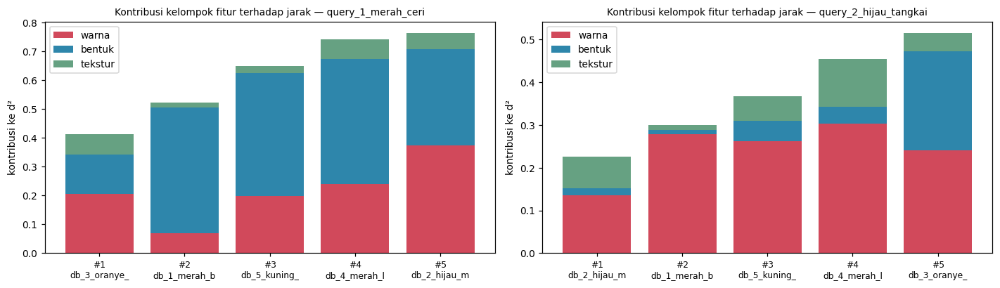

query_1_merah_ceri: peringkat 1 = db_3_oranye_ceri (d=0.643); porsi d² → warna 50.0%, bentuk 32.5%, tekstur 17.5%
query_2_hijau_tangkai: peringkat 1 = db_2_hijau_mentah (d=0.476); porsi d² → warna 60.0%, bentuk 7.4%, tekstur 32.7%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, qk in zip(axes, Q_KEYS):
    r = results[qk]; order = r["order"]; c = r["contrib"].iloc[order]
    bottom = np.zeros(5)
    for g, col in zip(FEATURE_GROUPS, ["#d1495b", "#2e86ab", "#66a182"]):
        ax.bar(range(5), c[g].values, bottom=bottom, label=g, color=col); bottom += c[g].values
    ax.set_xticks(range(5)); ax.set_xticklabels([f"#{i+1}\n{DB_KEYS[o][:12]}" for i, o in enumerate(order)], fontsize=8)
    ax.set_ylabel("kontribusi ke d²"); ax.set_title(f"Kontribusi kelompok fitur terhadap jarak — {qk}"); ax.legend()
plt.tight_layout(); plt.show()

for qk in Q_KEYS:
    r = results[qk]; top = r["order"][0]
    share = (r["contrib"].iloc[top] / r["contrib"].iloc[top].sum() * 100).round(1)
    print(f"{qk}: peringkat 1 = {DB_KEYS[top]} (d={r['d'][top]:.3f}); porsi d² → " + ", ".join(f"{g} {v}%" for g, v in share.items()))

**Penjelasan.** Grafik menumpuk kontribusi warna, bentuk, dan tekstur terhadap kuadrat jarak untuk tiap citra database (urut dari peringkat 1). Dari sini terlihat kelompok fitur mana yang "menarik" atau "menjauhkan" sebuah citra dari query — dasar untuk analisis pada langkah 7.

# Langkah 6 — Visualisasi Hasil Pencarian
## 6.1 Query 1 dan lima citra database terurut dari paling mirip hingga paling tidak mirip

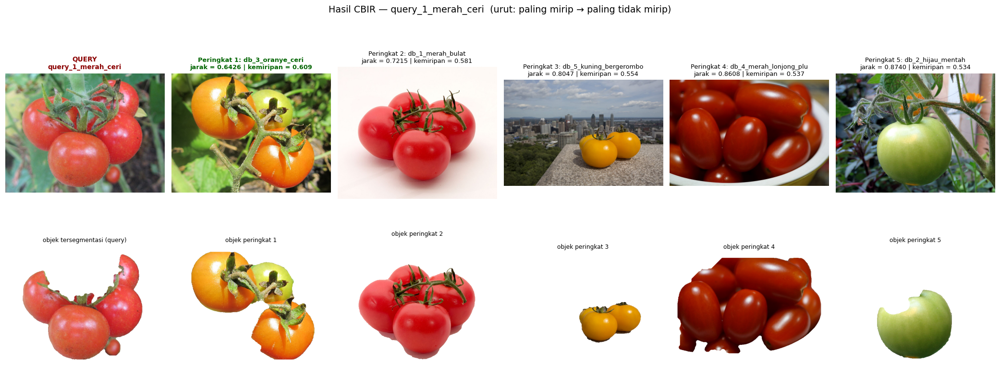

In [16]:
def show_cbir(qk, show_objects=True):
    r = results[qk]; order = r["order"]
    nrow = 2 if show_objects else 1
    fig, axes = plt.subplots(nrow, 6, figsize=(19, 3.9 * nrow)); axes = np.atleast_2d(axes)
    axes[0, 0].imshow(images[qk]); axes[0, 0].set_title(f"QUERY\n{qk}", color="darkred", fontweight="bold")
    for rank, idx in enumerate(order, start=1):
        k = DB_KEYS[idx]
        axes[0, rank].imshow(images[k])
        col = "darkgreen" if rank == 1 else "black"
        axes[0, rank].set_title(f"Peringkat {rank}: {k[:22]}\njarak = {r['d'][idx]:.4f} | kemiripan = {r['sim'][idx]:.3f}", color=col, fontsize=8.5,
                                fontweight="bold" if rank == 1 else "normal")
    if show_objects:
        axes[1, 0].imshow(object_only(images[qk], masks[qk])); axes[1, 0].set_title("objek tersegmentasi (query)", fontsize=8)
        for rank, idx in enumerate(order, start=1):
            axes[1, rank].imshow(object_only(images[DB_KEYS[idx]], masks[DB_KEYS[idx]])); axes[1, rank].set_title(f"objek peringkat {rank}", fontsize=8)
    for ax in axes.ravel(): ax.axis("off")
    plt.suptitle(f"Hasil CBIR — {qk}  (urut: paling mirip → paling tidak mirip)", fontsize=12.5, y=1.0)
    plt.tight_layout(); plt.show()

show_cbir(Q_KEYS[0])

## 6.2 Query 2 dan lima citra database terurut

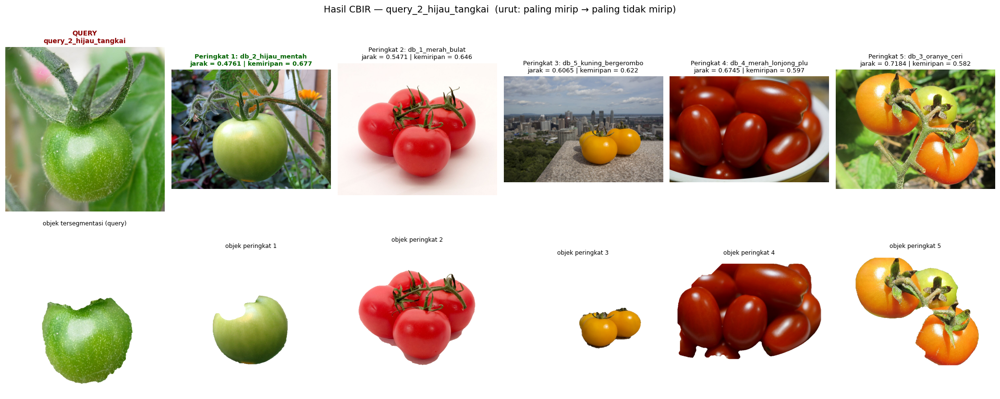

In [17]:
show_cbir(Q_KEYS[1])

**Penjelasan.** Baris atas: citra query (kiri) dan kelima citra database dari peringkat 1 (kiri) hingga 5 (kanan) lengkap dengan jarak Euclidean dan skor kemiripan. Baris bawah: objek hasil segmentasi yang sebenarnya dipakai untuk menghitung fitur.

## 6.3 Ringkasan peringkat kedua query dalam satu tabel

In [18]:
summary = pd.DataFrame({qk: [f"{DB_KEYS[i][:22]}  (d={results[qk]['d'][i]:.3f})" for i in results[qk]["order"]] for qk in Q_KEYS},
                       index=[f"Peringkat {i}" for i in range(1, 6)])
display(summary)

,query_1_merah_ceri,query_2_hijau_tangkai
Peringkat 1,db_3_oranye_ceri (d=0.643),db_2_hijau_mentah (d=0.476)
Peringkat 2,db_1_merah_bulat (d=0.722),db_1_merah_bulat (d=0.547)
Peringkat 3,db_5_kuning_bergerombo (d=0.805),db_5_kuning_bergerombo (d=0.606)
Peringkat 4,db_4_merah_lonjong_plu (d=0.861),db_4_merah_lonjong_plu (d=0.674)
Peringkat 5,db_2_hijau_mentah (d=0.874),db_3_oranye_ceri (d=0.718)


# Langkah 7 — Analisis
## 7.1 Pengujian pendukung analisis (dihitung otomatis oleh program)
Pengujian di bawah menjawab: apakah hasil sesuai pengamatan visual, dan bagaimana pilihan fitur/bobot/normalisasi memengaruhi peringkat.
### a) Kesesuaian dengan pengamatan visual
Relevansi ditentukan **secara visual berdasarkan kelas warna** (penilaian subjektif peneliti): untuk query merah → citra database bertomat merah (db_1, db_4); untuk query hijau → citra bertomat hijau (db_2).

In [19]:
RELEVANT = {Q_KEYS[0]: {"db_1_merah_bulat", "db_4_merah_lonjong_plum"},
            Q_KEYS[1]: {"db_2_hijau_mentah"}}
RELEVANT = {q: {k for k in v if k in DB_KEYS} for q, v in RELEVANT.items()}

def precision_at(order, rel, k):
    return np.mean([DB_KEYS[i] in rel for i in order[:k]])

def average_precision(order, rel):
    hits, s = 0, 0.0
    for r, i in enumerate(order, start=1):
        if DB_KEYS[i] in rel: hits += 1; s += hits / r
    return s / max(len(rel), 1)

rows = []
for qk in Q_KEYS:
    o = results[qk]["order"]
    rows.append({"query": qk, "peringkat 1": DB_KEYS[o[0]], "relevan menurut visual": ", ".join(sorted(RELEVANT[qk])),
                 "Precision@1": precision_at(o, RELEVANT[qk], 1), "Precision@2": precision_at(o, RELEVANT[qk], 2),
                 "Average Precision": round(average_precision(o, RELEVANT[qk]), 3)})
display(pd.DataFrame(rows).set_index("query"))

,peringkat 1,relevan menurut visual,Precision@1,Precision@2,Average Precision
query,,,,,
query_1_merah_ceri,db_3_oranye_ceri,"db_1_merah_bulat, db_4_merah_lonjong_plum",0.0,0.5,0.5
query_2_hijau_tangkai,db_2_hijau_mentah,db_2_hijau_mentah,1.0,0.5,1.0


### b) Pengaruh pilihan fitur dan bobot (ablasi kelompok fitur)
Peringkat dihitung ulang dengan memakai: warna saja, bentuk saja, tekstur saja, bobot utama (0,50/0,25/0,25), bobot sama rata (1/3 tiap kelompok), dan semua fitur dihitung sama (tanpa pembobotan kelompok).

In [20]:
def run_config(weights_by_group, normalize=True, metric="euclid"):
    wv = np.concatenate([np.full(len(c), weights_by_group.get(g, 0) / len(c)) for g, c in FEATURE_GROUPS.items()])
    out = {}
    for qi, qk in enumerate(Q_KEYS):
        Xd, q = (Xn_db, Xn_q[qi]) if normalize else (X_db, query_features.values.astype(float)[qi])
        if metric == "euclid": score = weighted_euclidean(Xd, q, wv); order = np.argsort(score)
        else: score = weighted_cosine(Xd, q, wv); order = np.argsort(-score)
        out[qk] = order
    return out

configs = {
    "warna saja":                  dict(w={"warna": 1}),
    "bentuk saja":                 dict(w={"bentuk": 1}),
    "tekstur saja":                dict(w={"tekstur": 1}),
    "warna+bentuk (0,5/0,5)":      dict(w={"warna": .5, "bentuk": .5}),
    "warna+tekstur (0,5/0,5)":     dict(w={"warna": .5, "tekstur": .5}),
    "UTAMA 0,50/0,25/0,25":        dict(w=GROUP_WEIGHTS),
    "sama rata 1/3 tiap kelompok": dict(w={"warna": 1/3, "bentuk": 1/3, "tekstur": 1/3}),
    "semua fitur sama (10:4:4)":   dict(w={"warna": 10/18, "bentuk": 4/18, "tekstur": 4/18}),
    "UTAMA tanpa normalisasi":     dict(w=GROUP_WEIGHTS, normalize=False),
    "UTAMA + kosinus":             dict(w=GROUP_WEIGHTS, metric="cos"),
}
abl = []
for name, cfg in configs.items():
    res = run_config(cfg["w"], cfg.get("normalize", True), cfg.get("metric", "euclid"))
    row = {"konfigurasi": name}
    for qk in Q_KEYS:
        row[f"{qk[:7]} urutan"] = " > ".join(DB_KEYS[i][3] for i in res[qk])
        row[f"{qk[:7]} P@1"] = precision_at(res[qk], RELEVANT[qk], 1)
    abl.append(row)
abl = pd.DataFrame(abl).set_index("konfigurasi")
display(Markdown("Keterangan urutan: angka = nomor citra database (1 = db_1, ..., 5 = db_5), dari paling mirip ke paling tidak mirip."))
display(abl)

Keterangan urutan: angka = nomor citra database (1 = db_1, ..., 5 = db_5), dari paling mirip ke paling tidak mirip.

,query_1 urutan,query_1 P@1,query_2 urutan,query_2 P@1
konfigurasi,,,,
warna saja,1 > 5 > 3 > 4 > 2,1.0,2 > 3 > 5 > 1 > 4,1.0
bentuk saja,3 > 2 > 5 > 4 > 1,0.0,1 > 2 > 4 > 5 > 3,0.0
tekstur saja,1 > 5 > 2 > 4 > 3,1.0,1 > 3 > 5 > 2 > 4,0.0
"warna+bentuk (0,5/0,5)",3 > 1 > 2 > 5 > 4,0.0,2 > 1 > 5 > 4 > 3,1.0
"warna+tekstur (0,5/0,5)",1 > 5 > 3 > 4 > 2,1.0,2 > 1 > 3 > 5 > 4,1.0
"UTAMA 0,50/0,25/0,25",3 > 1 > 5 > 4 > 2,0.0,2 > 1 > 5 > 4 > 3,1.0
sama rata 1/3 tiap kelompok,3 > 1 > 5 > 2 > 4,0.0,2 > 1 > 5 > 4 > 3,1.0
semua fitur sama (10:4:4),3 > 1 > 5 > 4 > 2,0.0,2 > 1 > 5 > 4 > 3,1.0
UTAMA tanpa normalisasi,5 > 4 > 2 > 1 > 3,0.0,5 > 1 > 2 > 4 > 3,0.0


### c) Keselarasan Euclidean vs kosinus dan pengaruh normalisasi

In [21]:
rows = []
for qk in Q_KEYS:
    r = results[qk]
    rho, _ = spearmanr(r["d"], -r["cos"]); tau, _ = kendalltau(r["d"], -r["cos"])
    Xq_raw = query_features.values.astype(float)[Q_KEYS.index(qk)]
    d_raw = np.sqrt((((X_db - Xq_raw) ** 2) * w_vec).sum(1))

    # fitur yang paling mendominasi jarak
    dom = pd.Series((((X_db - Xq_raw) ** 2) * w_vec).mean(0), index=FEATURE_ORDER).sort_values(ascending=False)
    rows.append({"query": qk, "Spearman (Euclid vs kosinus)": round(rho, 3), "Kendall tau": round(tau, 3),
                 "fitur dominan tanpa normalisasi": ", ".join(dom.index[:2])})
display(pd.DataFrame(rows).set_index("query"))

,Spearman (Euclid vs kosinus),Kendall tau,fitur dominan tanpa normalisasi
query,,,
query_1_merah_ceri,0.9,0.8,"contrast, hue_sin"
query_2_hijau_tangkai,1.0,1.0,"contrast, hue_cos"


### d) Fitur yang paling membedakan antar citra database

In [22]:
spread = pd.DataFrame({"std antar-database (ternormalisasi)": Xn_db.std(0),
                       "kelompok": [g for g, c in FEATURE_GROUPS.items() for _ in c]}, index=FEATURE_ORDER)
display(spread.sort_values("std antar-database (ternormalisasi)", ascending=False).round(3))

,std antar-database (ternormalisasi),kelompok
G_std,0.435,warna
R_mean,0.423,warna
correlation,0.415,tekstur
homogeneity,0.409,tekstur
B_mean,0.407,warna
G_mean,0.402,warna
aspect_ratio,0.382,bentuk
solidity,0.380,bentuk
S_mean,0.379,warna
energy,0.379,tekstur


### e) Jarak per kelompok fitur (kelompok mana yang menganggap citra database paling mirip?)
Untuk tiap kelompok dihitung jarak Euclidean pada fitur ternormalisasi, dirata-ratakan per dimensi (`sqrt(mean(Δ²))`) agar kelompok dengan jumlah dimensi berbeda dapat dibandingkan langsung. Nilai > 1 berarti query berada **di luar rentang database** untuk kelompok tersebut (min-max meng-ekstrapolasi).

In [23]:
rows = {}
for qi, qk in enumerate(Q_KEYS):
    i = 0
    for g, cols in FEATURE_GROUPS.items():
        sl = slice(i, i + len(cols)); i += len(cols)
        rows[(qk, g)] = np.sqrt(((Xn_db[:, sl] - Xn_q[qi, sl]) ** 2).mean(1))
grp = pd.DataFrame(rows, index=DB_KEYS).T
grp.index.names = ["query", "kelompok fitur"]
display(grp.round(3))
display(Markdown("**Citra database yang dianggap paling mirip oleh masing-masing kelompok fitur:**"))
display(grp.idxmin(axis=1).to_frame("paling mirip menurut kelompok"))

db_1_merah_bulat  db_2_hijau_mentah  db_3_oranye_ceri  db_4_merah_lonjong_plum  db_5_kuning_bergerombol
query                 kelompok fitur                                                                                                         
query_1_merah_ceri    warna                      0.371              0.865             0.642                    0.692                    0.630
                      bentuk                     1.322              1.153             0.733                    1.318                    1.305
                      tekstur                    0.242              0.479             0.538                    0.518                    0.303
query_2_hijau_tangkai warna                      0.746              0.522             0.693                    0.778                    0.723
                      bentuk                     0.206              0.258             0.965                    0.398                    0.442
                      tekstur                    0.206              0.544             0.417                    0.672                    0.481

**Citra database yang dianggap paling mirip oleh masing-masing kelompok fitur:**

paling mirip menurut kelompok
query                 kelompok fitur                              
query_1_merah_ceri    warna                       db_1_merah_bulat
                      bentuk                      db_3_oranye_ceri
                      tekstur                     db_1_merah_bulat
query_2_hijau_tangkai warna                      db_2_hijau_mentah
                      bentuk                      db_1_merah_bulat
                      tekstur                     db_1_merah_bulat

### f) Sensitivitas terhadap bobot warna
Bobot utama (0,50/0,25/0,25) ditetapkan lebih dulu dan **tidak diubah** setelah melihat hasil. Pengujian ini hanya untuk memahami seberapa kuat peringkat bergantung pada bobot: bobot warna divariasikan dari 0,20 sampai 1,00, sisanya dibagi sama rata untuk bentuk dan tekstur.

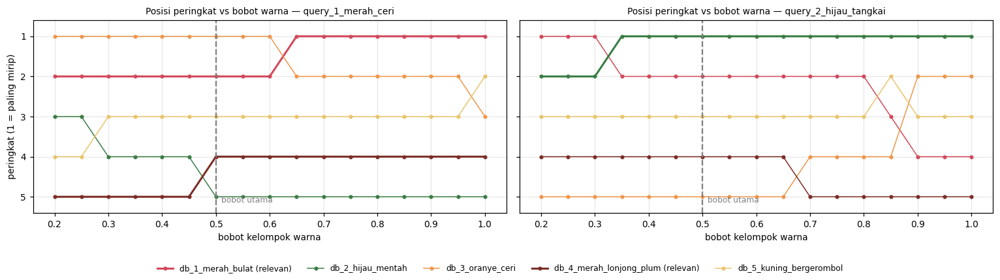

query_1_merah_ceri: peringkat 1 = citra relevan (menurut visual) bila bobot warna berada pada 0.65 s.d. 1.00  (bobot utama = 0.50)
query_2_hijau_tangkai: peringkat 1 = citra relevan (menurut visual) bila bobot warna berada pada 0.35 s.d. 1.00  (bobot utama = 0.50)


In [24]:
ws = np.round(np.arange(0.20, 1.0001, 0.05), 2)
rank_pos = {qk: {k: [] for k in DB_KEYS} for qk in Q_KEYS}
for wc in ws:
    res = run_config({"warna": wc, "bentuk": (1 - wc) / 2, "tekstur": (1 - wc) / 2})
    for qk in Q_KEYS:
        for pos, i in enumerate(res[qk], start=1): rank_pos[qk][DB_KEYS[i]].append(pos)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), sharey=True)
palette = dict(zip(DB_KEYS, ["#d1495b", "#3a7d44", "#ee964b", "#7b2d26", "#e9c46a"]))
for ax, qk in zip(axes, Q_KEYS):
    for k in DB_KEYS:
        ax.plot(ws, rank_pos[qk][k], "o-", ms=3, lw=2 if k in RELEVANT[qk] else 1, color=palette[k],
                label=k + (" (relevan)" if k in RELEVANT[qk] else ""))
    ax.axvline(GROUP_WEIGHTS["warna"], color="gray", ls="--"); ax.text(GROUP_WEIGHTS["warna"] + .01, 5.15, "bobot utama", fontsize=8, color="gray")
    ax.set_ylim(5.4, 0.6); ax.set_yticks(range(1, 6)); ax.set_xlabel("bobot kelompok warna"); ax.grid(alpha=.3)
    ax.set_title(f"Posisi peringkat vs bobot warna — {qk}")
axes[0].set_ylabel("peringkat (1 = paling mirip)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.show()

for qk in Q_KEYS:
    firsts = [DB_KEYS[run_config({"warna": wc, "bentuk": (1 - wc) / 2, "tekstur": (1 - wc) / 2})[qk][0]] for wc in ws]
    ok_range = [float(wc) for wc, f in zip(ws, firsts) if f in RELEVANT[qk]]
    teks = f"{min(ok_range):.2f} s.d. {max(ok_range):.2f}" if ok_range else "tidak ada"
    print(f"{qk}: peringkat 1 = citra relevan (menurut visual) bila bobot warna berada pada {teks}  (bobot utama = {GROUP_WEIGHTS['warna']:.2f})")

## 7.2 Analisis dan jawaban pertanyaan
_Catatan: angka-angka di bawah berasal dari eksekusi notebook ini terhadap kelima citra database dan dua citra query yang dipakai; jika citra berbeda, nilai dan peringkat dapat berbeda dan uraian harus disesuaikan dengan keluaran sel di atas._

### (a) Mengapa citra peringkat pertama paling mirip menurut fitur yang dipakai?

**Query 2 (`query_2_hijau_tangkai`) → peringkat 1: `db_2_hijau_mentah` (jarak 0,476; kemiripan 0,677).**
- **Warna menentukan.** Hue rata-rata query ≈ 85,7° dan db_2 ≈ 71,7° (keduanya kehijauan), sedangkan citra database lain berhue 1,8°–37,8° (merah, oranye, kuning). Jarak kelompok warna terkecil ada pada db_2 (0,52 dibanding 0,69–0,78 untuk yang lain; tabel 7.1e).
- **Bentuk dan tekstur tidak memilih db_2.** Pada kelompok bentuk dan tekstur, citra terdekat adalah db_1 (jarak bentuk 0,21 vs 0,26 untuk db_2; jarak tekstur 0,21 vs 0,54). Peringkat 1 jatuh ke db_2 karena kelompok warna menyumbang 60,0% dari kuadrat jarak (bentuk 7,4%, tekstur 32,7%).
- Kedua tomat sama-sama buah tunggal yang bulat (aspect ratio 1,072 vs 1,181; circularity 0,752 vs 0,692), sehingga jarak bentuk ke db_2 tetap kecil.

**Query 1 (`query_1_merah_ceri`) → peringkat 1: `db_3_oranye_ceri` (jarak 0,643; kemiripan 0,609).**
- Kelompok **warna** dan **tekstur** sebenarnya menganggap `db_1_merah_bulat` paling mirip (jarak warna 0,37 vs 0,64 untuk db_3; jarak tekstur 0,24 vs 0,54).
- Yang menarik query ke db_3 adalah kelompok **bentuk**: jarak bentuk ke db_3 hanya 0,73, sedangkan ke citra lain 1,15–1,32. Query_1 dan db_3 sama-sama gerombol buah dengan siluet tidak beraturan (circularity 0,367 vs 0,454; solidity 0,722 vs 0,845), sedangkan db_1 yang berlatar putih memiliki siluet lebih padat (circularity 0,731; solidity 0,945).
- Jarak bentuk > 1 menandakan nilai circularity dan solidity query berada **di luar rentang database** (min-max meng-ekstrapolasi), sehingga kelompok bentuk menyumbang 32,5% dari d² pada peringkat 1 padahal bobotnya hanya 0,25 (warna 50,0%, tekstur 17,5%).

### (b) Apakah hasilnya sesuai pengamatan visual?

Relevansi dinilai secara visual berdasarkan kelas warna (subjektif): query merah → db_1/db_4; query hijau → db_2.

| Query | Peringkat 1 | Precision@1 | Precision@2 | Average Precision |
|---|---|---|---|---|
| query_1_merah_ceri | db_3_oranye_ceri | 0,0 | 0,5 | 0,5 |
| query_2_hijau_tangkai | db_2_hijau_mentah | 1,0 | 0,5 | 1,0 |

- **Query 2: sesuai.** Tomat hijau mentah menemukan tomat hijau mentah di peringkat pertama.
- **Query 1: hanya sebagian sesuai.** Tomat merah yang paling mirip menurut pengamatan visual (`db_1`) berada di **peringkat 2**, tetapi peringkat 1 adalah tomat oranye (`db_3`), dan tomat plum merah tua (`db_4`) justru di peringkat 4. Secara visual oranye dan merah matang berbeda tingkat kematangan, jadi peringkat 1 ini kurang tepat. Penyebabnya sudah teridentifikasi pada (a): kelompok bentuk, bukan warna.
- Tomat plum (`db_4`) tertinggal pada kelompok warna karena foto itu jauh lebih **gelap** (rata-rata R dan V ≈ 0,50 dibanding 0,81 pada query_1). Mean RGB dan V peka terhadap kecerahan foto, bukan hanya warna tomat.

### (c) Bagaimana fitur yang dipilih memengaruhi peringkat?

Hasil ablasi (tabel 7.1b), urutan nomor citra database dari paling mirip:

| Konfigurasi | Query 1 | Query 2 |
|---|---|---|
| warna saja | 1 > 5 > 3 > 4 > 2 (P@1 = 1) | 2 > 3 > 5 > 1 > 4 (P@1 = 1) |
| bentuk saja | 3 > 2 > 5 > 4 > 1 (P@1 = 0) | 1 > 2 > 4 > 5 > 3 (P@1 = 0) |
| tekstur saja | 1 > 5 > 2 > 4 > 3 (P@1 = 1) | 1 > 3 > 5 > 2 > 4 (P@1 = 0) |
| **utama 0,50/0,25/0,25** | 3 > 1 > 5 > 4 > 2 (P@1 = 0) | 2 > 1 > 5 > 4 > 3 (P@1 = 1) |
| tanpa normalisasi | 5 > 4 > 2 > 1 > 3 (P@1 = 0) | 5 > 1 > 2 > 4 > 3 (P@1 = 0) |

- **Warna** adalah penentu paling informatif untuk membedakan kematangan: sendirian ia sudah menempatkan citra relevan di peringkat 1 pada kedua query.
- **Bentuk** tidak peka terhadap warna dan menempatkan citra yang salah di peringkat 1 pada kedua query (db_3 untuk query_1, db_1 untuk query_2); pada konfigurasi utama ia hanya merugikan query_1.
- **Tekstur** tidak membedakan warna: untuk query_2 ia menaruh tomat merah `db_1` di peringkat 1, sehingga tidak cukup dipakai sendirian.
- **Normalisasi sangat menentukan.** Tanpa min-max, fitur berskala besar (terutama `contrast` GLCM) mendominasi jarak, dan P@1 jatuh menjadi 0 pada kedua query. Ini sesuai pembahasan materi bahwa fitur berskala besar menutupi fitur lain.
- **Euclidean vs kosinus:** peringkat 1 sama untuk kedua query; korelasi Spearman 0,9 (query_1) dan 1,0 (query_2). Bobot sama rata (1/3) hanya menukar urutan peringkat 4–5 pada query_1, dan bobot proporsional dimensi (10:4:4) menghasilkan urutan yang sama dengan bobot utama.
- **Sensitivitas bobot (7.1f).** Bobot utama tidak diubah, tetapi pemindaian menunjukkan peringkat 1 untuk query_1 menjadi citra relevan (`db_1`) bila bobot warna ≥ 0,65, sedangkan untuk query_2 sudah benar sejak bobot warna ≥ 0,35. Artinya hasil query_1 **rapuh terhadap pilihan bobot**: dua citra teratas hanya terpaut 0,08 pada skala jarak (0,643 vs 0,722), dan dengan hanya dua query tidak ada dasar yang kuat untuk menyetel bobot agar "pas".

### (d) Keterbatasan pendekatan yang dibuat

1. **Database sangat kecil (5 citra).** Parameter min-max diambil dari lima citra saja sehingga mudah berubah bila ada satu citra tambahan, dan query yang berada di luar rentang database (seperti bentuk query_1) menghasilkan jarak ekstrapolasi yang besar. Dengan dua query, hasil tidak dapat digeneralisasi secara statistik.
2. **Fitur warna peka terhadap pencahayaan.** Mean/std RGB dan V ikut berubah bila foto lebih gelap/terang (kasus db_4). Representasi yang lebih tahan cahaya (misalnya hanya hue dan saturasi, histogram hue, atau ruang warna L\*a\*b\*) layak dicoba.
3. **Fitur bentuk dihitung pada seluruh mask sekaligus.** Gerombol buah membuat siluet tidak beraturan sehingga bentuk "satu tomat" tidak terwakili; tomat yang bertumpuk (db_4) menyatu menjadi satu objek. Area dan perimeter bergantung pada jarak pemotretan sehingga tidak dimasukkan ke vektor.
4. **Kualitas segmentasi memengaruhi seluruh fitur.** Bagian atas buah db_2 terpotong oleh pantulan cahaya, sisa kelopak/tangkai yang tebal pada gerombol (db_3, query_1) tidak seluruhnya terbuang sedangkan yang tipis terbuang, dan terdapat takik kecil pada tepi query_1. Tidak ada mask acuan (ground truth) selain validasi IoU sederhana pada db_1.
5. **GLCM bergantung pada resolusi dan fokus foto** (objek berlatar kabur seperti query_2 berbeda dengan latar tajam), meskipun semua citra sudah diseragamkan ukurannya.
6. **Bobot kelompok ditetapkan manual**, bukan dipelajari dari data; relevansi hanya ditentukan secara visual dan subjektif (kelas warna).
7. **Fitur global kehilangan informasi lokal/spasial**, misalnya jumlah buah, letak tangkai, atau detail permukaan. Fitur lokal (misalnya ORB pada langkah 8) menyimpan informasi tersebut dan dapat melengkapi, atau sistem dapat dikembangkan dengan _bag of visual words_.

**Perbaikan yang disarankan:** menambah jumlah citra database, memakai fitur warna yang tahan pencahayaan, menghitung bentuk per buah (misalnya dengan watershed), mempelajari bobot dengan validasi, dan menggabungkan fitur global dengan fitur lokal.

# Langkah 8 — Ekstraksi Fitur Lokal ORB
Bagian ini terpisah dari CBIR fitur global dan **tidak mengubah hasil pemeringkatan**. Hanya ORB yang dipakai (tanpa Harris, SIFT, SURF, atau RANSAC), sesuai ketentuan tugas.

## 8.1 Memilih satu citra dan memutarnya ±20°

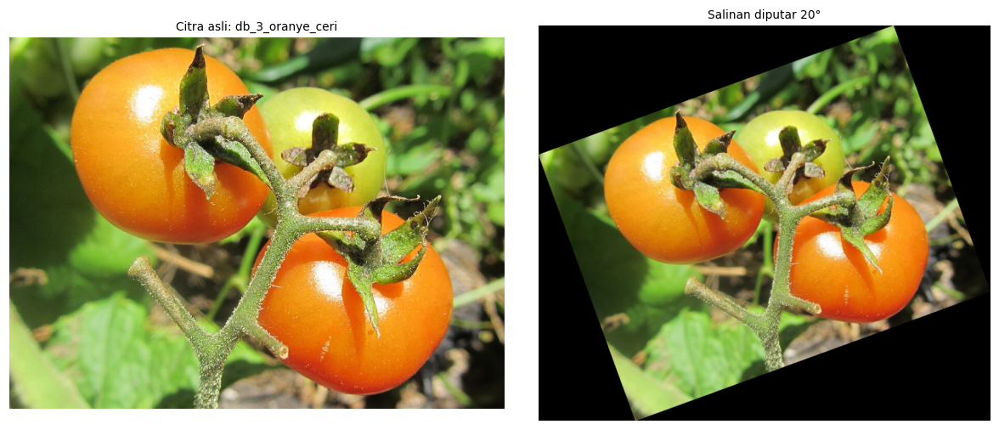

In [25]:
ORB_KEY = "db_3_oranye_ceri"
ANGLE = 20

img_a = images[ORB_KEY]
h, w = img_a.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), ANGLE, 1.0)
cos_, sin_ = abs(M[0, 0]), abs(M[0, 1])
new_w, new_h = int(h * sin_ + w * cos_), int(h * cos_ + w * sin_)
M[0, 2] += new_w / 2 - w / 2; M[1, 2] += new_h / 2 - h / 2
img_b = cv2.warpAffine(img_a, M, (new_w, new_h), borderValue=(0, 0, 0))     #

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].imshow(img_a); ax[0].set_title(f"Citra asli: {ORB_KEY}"); ax[1].imshow(img_b); ax[1].set_title(f"Salinan diputar {ANGLE}°")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Penjelasan.** Salinan citra diputar 20° dengan kanvas diperbesar agar tidak ada bagian yang terpotong.

## 8.2 ORB: keypoint dan descriptor pada kedua citra

Citra asli   : 1000 keypoint, descriptor (1000, 32) (uint8 → 256 bit)
Citra rotasi : 1000 keypoint, descriptor (1000, 32)


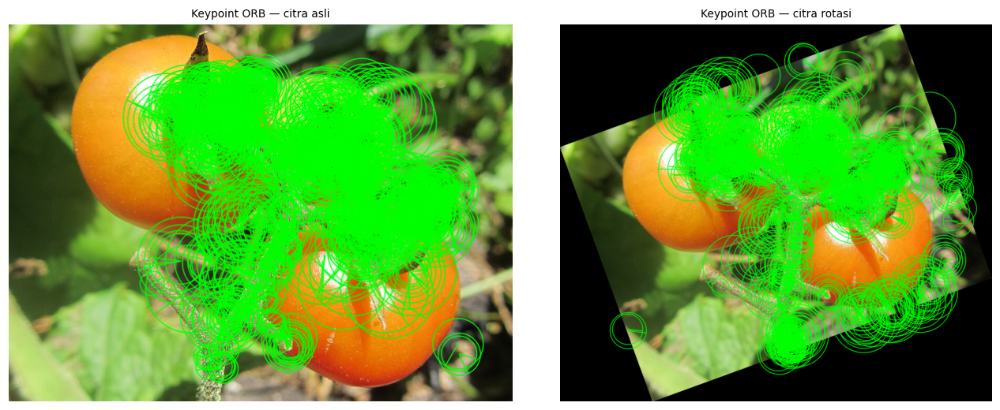

In [26]:
gray_a, gray_b = cv2.cvtColor(img_a, cv2.COLOR_RGB2GRAY), cv2.cvtColor(img_b, cv2.COLOR_RGB2GRAY)
orb = cv2.ORB_create(nfeatures=1000)
kp_a, des_a = orb.detectAndCompute(gray_a, None)
kp_b, des_b = orb.detectAndCompute(gray_b, None)
print(f"Citra asli   : {len(kp_a)} keypoint, descriptor {des_a.shape} (uint8 → {des_a.shape[1]*8} bit)")
print(f"Citra rotasi : {len(kp_b)} keypoint, descriptor {des_b.shape}")

vis_a = cv2.drawKeypoints(img_a, kp_a, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
vis_b = cv2.drawKeypoints(img_b, kp_b, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].imshow(vis_a); ax[0].set_title("Keypoint ORB — citra asli"); ax[1].imshow(vis_b); ax[1].set_title("Keypoint ORB — citra rotasi")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Penjelasan.** ORB (_Oriented FAST and Rotated BRIEF_, materi P18) mendeteksi keypoint dengan **FAST** pada piramida citra (multi-skala), memberi **orientasi** dengan _intensity centroid_, lalu menghitung descriptor biner **rBRIEF 256 bit** yang diputar mengikuti orientasi tersebut. Lingkaran dengan garis pada gambar menunjukkan skala dan orientasi tiap keypoint.

## 8.3 Pencocokan dengan BFMatcher (jarak Hamming) dan visualisasi

Jumlah pasangan cocok (cross-check): 617
Jarak Hamming: min = 3, median = 19.0, maks = 77 (dari 256 bit)


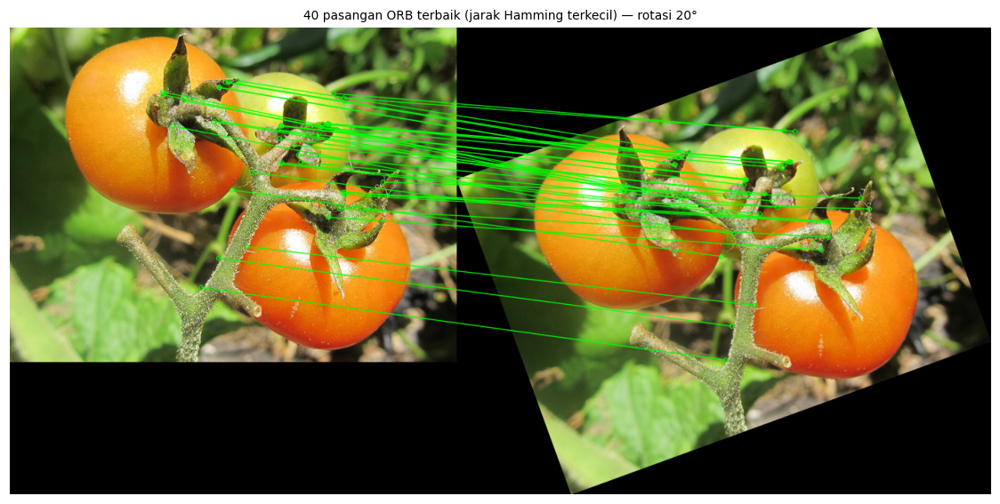

Pasangan yang posisinya sesuai rotasi sebenarnya (galat < 5 px): 600 dari 617 (97.2%)
Pada 40 pasangan terbaik: 40 dari 40 sesuai.


In [27]:
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des_a, des_b), key=lambda m: m.distance)
print(f"Jumlah pasangan cocok (cross-check): {len(matches)}")
print(f"Jarak Hamming: min = {matches[0].distance:.0f}, median = {np.median([m.distance for m in matches]):.1f}, maks = {matches[-1].distance:.0f} (dari 256 bit)")

vis = cv2.drawMatches(img_a, kp_a, img_b, kp_b, matches[:40], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
                      matchColor=(0, 255, 0), singlePointColor=(255, 0, 0))
plt.figure(figsize=(15, 6.2)); plt.imshow(vis); plt.axis("off")
plt.title(f"40 pasangan ORB terbaik (jarak Hamming terkecil) — rotasi {ANGLE}°"); plt.show()

pa = np.float32([kp_a[m.queryIdx].pt for m in matches]); pb = np.float32([kp_b[m.trainIdx].pt for m in matches])
pred = cv2.transform(pa.reshape(-1, 1, 2), M).reshape(-1, 2)
err = np.linalg.norm(pred - pb, axis=1)
print(f"Pasangan yang posisinya sesuai rotasi sebenarnya (galat < 5 px): {(err < 5).sum()} dari {len(matches)} ({100*(err<5).mean():.1f}%)")
print(f"Pada 40 pasangan terbaik: {(err[:40] < 5).sum()} dari 40 sesuai.")

**Penjelasan.** `BFMatcher` dengan `NORM_HAMMING` membandingkan descriptor biner dengan XOR dan penghitungan bit (_popcount_), seperti contoh Hamming pada materi P18; `crossCheck=True` hanya mempertahankan pasangan yang saling menjadi tetangga terdekat. Garis hijau menghubungkan keypoint yang cocok pada kedua citra. Karena rotasi yang dipakai diketahui, kebenaran pasangan dapat diverifikasi dengan menerapkan rotasi tersebut pada posisi keypoint citra asli dan membandingkannya dengan posisi pasangannya (bukan RANSAC).

## 8.4 (Pelengkap) Jumlah pasangan terhadap sudut rotasi

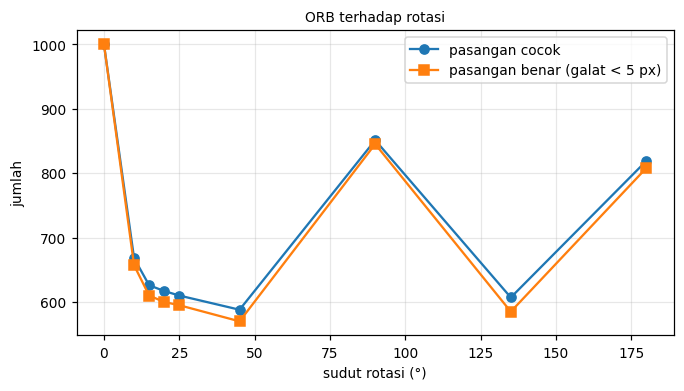

sudut (°),0,10,15,20,25,45,90,135,180
pasangan cocok,1000,668,626,617,610,588,851,607,819
pasangan benar,1000,657,610,600,595,570,845,585,808


In [28]:
angles = [0, 10, 15, 20, 25, 45, 90, 135, 180]
counts, good = [], []
for a in angles:
    Mx = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
    c_, s_ = abs(Mx[0, 0]), abs(Mx[0, 1]); nw, nh = int(h * s_ + w * c_), int(h * c_ + w * s_)
    Mx[0, 2] += nw / 2 - w / 2; Mx[1, 2] += nh / 2 - h / 2
    gb = cv2.cvtColor(cv2.warpAffine(img_a, Mx, (nw, nh), borderValue=(0, 0, 0)), cv2.COLOR_RGB2GRAY)
    kb, db_ = orb.detectAndCompute(gb, None)
    mt = bf.match(des_a, db_)
    p1 = np.float32([kp_a[m.queryIdx].pt for m in mt]); p2 = np.float32([kb[m.trainIdx].pt for m in mt])
    e = np.linalg.norm(cv2.transform(p1.reshape(-1, 1, 2), Mx).reshape(-1, 2) - p2, axis=1)
    counts.append(len(mt)); good.append(int((e < 5).sum()))
plt.figure(figsize=(7, 3.6)); plt.plot(angles, counts, "o-", label="pasangan cocok"); plt.plot(angles, good, "s-", label="pasangan benar (galat < 5 px)")
plt.xlabel("sudut rotasi (°)"); plt.ylabel("jumlah"); plt.grid(alpha=.3); plt.legend(); plt.title("ORB terhadap rotasi"); plt.show()
display(pd.DataFrame({"sudut (°)": angles, "pasangan cocok": counts, "pasangan benar": good}).set_index("sudut (°)").T)

## 8.5 Kesimpulan percobaan ORB
**Ya, setelah rotasi 20° masih ditemukan banyak pasangan titik** yang cocok (lihat jumlah pasangan dan persentase pasangan benar pada keluaran 8.3; pada eksekusi kami ratusan pasangan dan hampir seluruhnya sesuai rotasi sebenarnya). Hal ini karena ORB memberi tiap keypoint **orientasi** (intensity centroid) lalu **memutar pola pembanding BRIEF mengikuti orientasi itu**, sehingga descriptor tetap hampir sama walau citra berputar. Fitur lokal juga hanya bergantung pada pola di sekitar titik-titik khas (bukan keseluruhan citra), sehingga dapat mengenali objek/citra yang sama pada sudut berbeda.

Grafik 8.4 menunjukkan jumlah pasangan **menurun pada rotasi sedang** (10°–45°) karena interpolasi saat memutar mengubah nilai piksel sehingga descriptor sedikit bergeser, namun tetap ratusan dan tidak hilang. Jumlahnya **naik kembali pada 90° dan 180°**, kemungkinan karena rotasi kelipatan 90° hanya menata ulang piksel tanpa interpolasi. Berbeda dengan fitur global CBIR yang memadatkan seluruh citra menjadi satu vektor, fitur lokal mempertahankan banyak titik khas sehingga lebih tahan terhadap rotasi dan sebagian oklusi.

# Kesimpulan Umum
1. Segmentasi dua tahap (GrabCut + penyaringan warna dominan HSV) menghasilkan mask yang layak untuk ketujuh citra meskipun latar sangat beragam; keterbatasannya (sisa kelopak pada gerombol dan pantulan cahaya di tepi buah) dijelaskan pada langkah 2.3.
2. Tiga kelompok fitur global (warna, bentuk, tekstur GLCM) diekstraksi **hanya dari objek**, dengan satu fungsi yang sama untuk citra database dan query.
3. CBIR dibangun dengan normalisasi min-max, pembobotan kelompok, jarak Euclidean berbobot, dan pembanding kosinus; **peringkat dihitung program** (`np.argsort`).
4. Fitur lokal ORB (opsional) tetap menemukan pasangan titik pada citra yang diputar, berbeda dengan fitur global yang merepresentasikan seluruh citra dalam satu vektor.

### Daftar Pustaka / Materi
- Materi kuliah P17 — _Ekstraksi Fitur Global & Deteksi Fitur_ (warna, bentuk, tekstur/GLCM, CBIR).
- Materi kuliah P18 — _Ekstraksi Fitur Lokal_ (ORB: oFAST + rBRIEF, jarak Hamming, BFMatcher).
- Rother, C., Kolmogorov, V. & Blake, A. (2004) "GrabCut: Interactive Foreground Extraction using Iterated Graph Cuts", _ACM TOG_ 23(3).
- Haralick, R. M., Shanmugam, K. & Dinstein, I. (1973) "Textural Features for Image Classification", _IEEE Trans. SMC_ 3(6).
- Rublee, E. et al. (2011) "ORB: An efficient alternative to SIFT or SURF", _ICCV_.
- Sumber citra: Wikimedia Commons (lihat tabel pada Langkah 1.2).